# LABS-10: Analytics Project

In this notebook you will run and edit the code to perform some data cleaning and run a basic kNN model.

> **What is kNN?**\
k-Nearest Neighbors (kNN) is a machine learning algorithm used for classification tasks. At its core, kNN works by measuring the "distance" between data points. When you want to predict the category of a new data point, kNN looks at the 'k' closest points in your dataset (its "neighbors") and assigns the most common category among those neighbors to the new point.

> **How does kNN measure distance?**\
kNN relies on distance metrics - commonly Euclidean distance (the straight-line distance between two points) - to find which data points are most similar. The algorithm compares all features (columns) in your dataset, so it's important that these features are numeric or converted to a format where distances can be calculated.

> **How will we use kNN here?**\
In this notebook, we'll use kNN for classification: predicting whether a movie will receive a "high" or "low" score based on its features (like genre, country, budget, and more). By carefully cleaning and formatting our data, we ensure that kNN can measure distances and make meaningful predictions.

**Data**\
This dataset comes from IMDB and can be accessed on [Kaggle](https://www.kaggle.com/datasets/ashpalsingh1525/imdb-movies-dataset).

**Paul Chen | DS1001 | November 5, 2026 | GitHub: PaulChen0508**

Data source: the [Kaggle dataset linked in the original notebook](https://www.kaggle.com/datasets/ashpalsingh1525/imdb-movies-dataset), downloaded unchanged. Score threshold: 65, informed by the LABS-7 density plot. The starter score-indexing bug is corrected and numeric scaling is fitted after the train/test split. The random seed remains 45.


## Set up environment

In [1]:
# Import packages
from pathlib import Path
import hashlib
import json
import platform
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

Path('figures/lab10').mkdir(parents=True, exist_ok=True)
Path('results/lab10').mkdir(parents=True, exist_ok=True)
print('Paul Chen | DS1001 | GitHub: PaulChen0508')
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)


Paul Chen | DS1001 | GitHub: PaulChen0508
Python: 3.14.2 | scikit-learn: 1.9.1


In [2]:
# The unchanged CSV downloaded from the dataset linked in this notebook
data_path = Path('data/raw/imdb_movies.csv')
data = pd.read_csv(data_path)
print('Rows and columns:', data.shape)
print('CSV SHA-256:', hashlib.sha256(data_path.read_bytes()).hexdigest())
data.head()


Rows and columns: (10178, 12)
CSV SHA-256: acefbb7fb126eb9365b8ba2121d2c1d98cd1ede7c759b08d2315d69cfffd6ee1


,names,date_x,score,genre,overview,crew,orig_title,status,orig_lang,budget_x,revenue,country
0,Creed III,03/02/2023,73.0,"Drama, Action","After dominating the boxing world, Adonis Cree...","Michael B. Jordan, Adonis Creed, Tessa Thompso...",Creed III,Released,English,75000000.0,2.716167e+08,AU
1,Avatar: The Way of Water,12/15/2022,78.0,"Science Fiction, Adventure, Action",Set more than a decade after the events of the...,"Sam Worthington, Jake Sully, Zoe Saldaña, Neyt...",Avatar: The Way of Water,Released,English,460000000.0,2.316795e+09,AU
2,The Super Mario Bros. Movie,04/05/2023,76.0,"Animation, Adventure, Family, Fantasy, Comedy","While working underground to fix a water main,...","Chris Pratt, Mario (voice), Anya Taylor-Joy, P...",The Super Mario Bros. Movie,Released,English,100000000.0,7.244590e+08,AU
3,Mummies,01/05/2023,70.0,"Animation, Comedy, Family, Adventure, Fantasy","Through a series of unfortunate events, three ...","Óscar Barberán, Thut (voice), Ana Esther Albor...",Momias,Released,"Spanish, Castilian",12300000.0,3.420000e+07,AU
4,Supercell,03/17/2023,61.0,Action,Good-hearted teenager William always lived in ...,"Skeet Ulrich, Roy Cameron, Anne Heche, Dr Quin...",Supercell,Released,English,77000000.0,3.409420e+08,US


## Data Cleaning & Model Prep

Before building a machine learning model, it is essential to clean and format the data. Raw data often contains missing values, inconsistent formats, or irrelevant information that can negatively impact or break a model.\
Many algorithms, including kNN, require numeric input or specificly formatted categorical data. By cleaning the data (removing or imputing missing values, converting strings to categorical variables, and creating dummy variables), we ensure that our dataset is structured in a way that the model can interpret and learn from effectively.

Proper data preparation leads to more accurate, reliable, and interpretable results.

There are many decisions that get made throughout this process and there is often no "right" answer - so documentating why you do things as you clean data is **key**.

### Missing Values

We saw in our design lab that some of our columns are missing values. Many models can not tolerate missing data (they will break the model), so we have to deal with these before passing the data through to our model.

We can use the [`.info()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.info.html#pandas.DataFrame.info) method to see what columns are missing data. Run this below (look back at LABS-06 if you don't remember how).

In [3]:
# Inspect the original data before removing missing values
data.info()
print()
print('Missing entries per column:')
print(data.isna().sum().to_string())


<class 'pandas.DataFrame'>
RangeIndex: 10178 entries, 0 to 10177
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   names       10178 non-null  str    
 1   date_x      10178 non-null  str    
 2   score       10178 non-null  float64
 3   genre       10093 non-null  str    
 4   overview    10178 non-null  str    
 5   crew        10122 non-null  str    
 6   orig_title  10178 non-null  str    
 7   status      10178 non-null  str    
 8   orig_lang   10178 non-null  str    
 9   budget_x    10178 non-null  float64
 10  revenue     10178 non-null  float64
 11  country     10178 non-null  str    
dtypes: float64(3), str(9)
memory usage: 954.3 KB

Missing entries per column:


names          0
date_x         0
score          0
genre         85
overview       0
crew          56
orig_title     0
status         0
orig_lang      0
budget_x       0
revenue        0
country        0


2 columns are missing data: `genre` and `crew`.\
Since we have a large data set for kNN, we can drop the relatively few rows that are missing data using .dropna()

In [4]:
## make a new df to make changes to
model_data = data.copy()

In [5]:
# Drop rows with at least one missing value
model_data.dropna(inplace=True)
print('Original rows:', len(data))
print('Rows retained:', len(model_data))
print('Rows dropped:', len(data) - len(model_data))


Original rows: 10178
Rows retained: 10052
Rows dropped: 126


Now that we've dropped rows with missing values, our dataset is free of NaNs.
>The output of the cell below (`model_data.info()`) confirms that all columns are complete and can be used to answer **question 1** regarding how much data was removed.

In [6]:
model_data.info()

<class 'pandas.DataFrame'>
Index: 10052 entries, 0 to 10177
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   names       10052 non-null  str    
 1   date_x      10052 non-null  str    
 2   score       10052 non-null  float64
 3   genre       10052 non-null  str    
 4   overview    10052 non-null  str    
 5   crew        10052 non-null  str    
 6   orig_title  10052 non-null  str    
 7   status      10052 non-null  str    
 8   orig_lang   10052 non-null  str    
 9   budget_x    10052 non-null  float64
 10  revenue     10052 non-null  float64
 11  country     10052 non-null  str    
dtypes: float64(3), str(9)
memory usage: 1020.9 KB


### Look at Columns

When preparing data for kNN, it's important to look at the values in each column, especially for columns with categories (like country or genre).\
kNN works by measuring the distance between data points to find the ones that are most similar, so if a column has too many different categories, it can make these distance calculations confusing and less useful. If some categories only appear a few times, they don't help much and can make the model less accurate.

To fix this, we can group these less common categories into a single 'other' category. This makes the data simpler and helps kNN focus on the most useful information when measuring distances.

In [7]:
data['status'].value_counts()

status
Released           10131
Post Production       31
In Production         16
Name: count, dtype: int64

The `status` column has 3 levels (3 distrinct values in the column). This works great for kNN!

Now let's take a look at `country`.

In [8]:
data['country'].value_counts()

country
AU    4885
US    2750
JP     538
KR     361
FR     222
GB     174
ES     153
HK     125
IT     123
MX     105
CN      93
DE      88
CA      67
RU      52
PH      43
IN      43
AR      41
BR      38
TH      30
DK      24
PL      22
TR      20
NO      16
NL      16
CO      14
TW      13
ID      12
IE      11
CL       9
SE       9
BE       7
PE       7
FI       6
GR       6
CH       5
SU       5
UA       4
SG       4
ZA       3
VN       3
HU       3
IS       2
GT       2
CZ       2
PR       2
SK       2
UY       2
AT       2
MY       2
IR       2
IL       1
DO       1
BO       1
BY       1
PY       1
MU       1
LV       1
XC       1
PT       1
KH       1
Name: count, dtype: int64

`country` has far too many columns to use in kNN. We need to collapse the smaller countries into a single "other" category.

In the next code cell, you will run the code to do this.

#### Collapse the `country` column

The cell below contains the code to collapse the `country` column reassign any coutries with less occurances than the threshold to have the value 'other'.

> *Hint: Look at the variable assignment in the cell below to identify where the threshold for grouping countries is set to help answer **question 3**. Notice where this is used in the line below the does the actual collapsing.*

In [9]:
# Keep a country only when it appears more than 100 times
country_threshold = 100
country_counts = model_data['country'].value_counts()
model_data['country'] = model_data['country'].where(
    model_data['country'].map(country_counts) > country_threshold, 'other')


In [10]:
# check the new counts after collapsing

model_data['country'].value_counts()


country
AU       4880
US       2716
other     709
JP        502
KR        358
FR        219
GB        172
ES        151
IT        123
HK        120
MX        102
Name: count, dtype: int64

Now the `country` column has 11 levels, including our new "other" category. This is still a little large for kNN, but we can always come back and adjust this if we find our model needs some tinkering.

#### Look at other problematic columns

Now let's check out some of the other categorical columns that we'll use and see if we need to collapse or simplify any of them.

In [11]:
# Check values for 'genre' column

model_data['genre'].value_counts()

genre
Drama                                                   556
Comedy                                                  373
Drama, Romance                                          268
Horror                                                  258
Horror, Thriller                                        202
                                                       ... 
History, Drama, Family                                    1
Adventure, Fantasy, Animation, Comedy, Family             1
Adventure, Comedy, Family, Science Fiction, Action        1
Mystery, Thriller, Comedy                                 1
Action, Adventure, Science Fiction, Thriller, Horror      1
Name: count, Length: 2300, dtype: int64

In [12]:
# Check values for 'orig_lang' column

model_data['orig_lang'].value_counts()

orig_lang
English                                7381
Japanese                                675
Spanish, Castilian                      388
Korean                                  384
French                                  282
Chinese                                 144
Italian                                 142
Cantonese                               141
German                                   89
Russian                                  65
Tagalog                                  42
Portuguese                               35
Thai                                     33
Norwegian                                29
Polish                                   26
Hindi                                    26
Danish                                   23
Swedish                                  22
Dutch, Flemish                           21
Turkish                                  21
Indonesian                               11
Finnish                                   6
Telugu                

Both the `genre` and `orig_lang` columns often contain multiple values separated by commas within a single cell (for example, "Animation, Adventure, Family" or "Spanish, Castilian"). This means that instead of just one value, each cell can list several genres or languages for a movie.

This is too complex for machine learning models like kNN, which work best when each column contains just one clear value per row. To make things simpler and easier to model, we will only keep the first value from each cell. This way, each movie will have just one genre and one language listed, making our data cleaner and better suited for the modeling we are doing.


#### Get the first value for `genre` and `orig_lang`


This process happens in three steps:

1. **Define the function:**  
    To simplify columns that contain lists of values, we we use a **function** - a reusable block of code that performs a specific task. Think of a function like a mini-program: you give it some input, it does something for you, and gives you back a result. Here, our function will extract just the first value from each cell to simplify the data so each row has only one value per column.

2. **Apply the function:**  
    We then apply this function to the `genre` and `orig_lang` columns, creating new columns called `top_genre` and `top_lang` with just the top value for each movie.

3. **Recheck the counts:**  
    After this step, we check how many unique values remain in these simplified columns to confirm that our data is now easier to work with.

In [13]:
# Extract the first comma-separated value, removing surrounding whitespace
def get_top_value(old_column_name, new_column_name):
    model_data[new_column_name] = (
        model_data[old_column_name].astype(str).str.split(',').str[0].str.strip()
    )


In [14]:
# apply the function to the 'genre' and 'orig_lang' columns

get_top_value('genre', 'top_genre')
get_top_value('orig_lang', 'top_lang')

In [15]:
# Check the counts again

display(model_data['top_genre'].value_counts(),
        model_data['top_lang'].value_counts())

top_genre
Drama              1865
Action             1563
Comedy             1377
Horror              931
Animation           885
Thriller            577
Adventure           571
Romance             413
Crime               371
Family              333
Science Fiction     313
Fantasy             263
Documentary         176
Mystery             108
War                  77
Music                76
Western              72
History              46
TV Movie             35
Name: count, dtype: int64

top_lang
English           7381
Japanese           675
Spanish            388
Korean             384
French             282
Chinese            144
Italian            142
Cantonese          141
German              89
Russian             65
Tagalog             42
Portuguese          35
Thai                33
Norwegian           29
Polish              26
Hindi               26
Danish              23
Swedish             22
Dutch               21
Turkish             21
Indonesian          11
Finnish              6
Telugu               6
Greek                6
Tamil                5
Ukrainian            4
Arabic               4
Persian              4
Icelandic            3
Vietnamese           3
Malayalam            3
Catalan              2
Romanian             2
Hungarian            2
Malay                2
Czech                2
Kannada              2
Macedonian           1
Serbian              1
Galician             1
Oriya                1
Bengali              1
Bokmål               1
La

The `top_genre` column now has 19 different values, which is easier for kNN to work with than the original genre data that had lots of combinations. By simplifying this column, the distance calculations in the model will have more meaning. If we notice that some genres are still very rare or if our model isn’t working well, we can always come back and group those rare genres into an "other" category to make things even simpler.


For the `top_lang` column, we’ve also made things easier by keeping only the main language for each movie. But some languages only show up a few times, which can overly-complicate the distance calculations in the model. To fix this, we should group these less common languages into an "other" category, just like we did for the `country` column. This helps the most important languages have meaning and avoids over-complicating the model with the ones that don’t appear often.

The cell below contains the code to collapse the `top_lang` column reassign any languages with less occurances than the threshold to have the value 'other'.

> *Hint: Look at the variable assignment in the cell below to identify where the threshold for grouping languages is set to help answer **question 3**. Notice where this is used in the line below the does the actual collapsing.*

In [16]:
# Keep a language only when it appears more than 10 times
language_threshold = 10
language_counts = model_data['top_lang'].value_counts()
model_data['top_lang'] = model_data['top_lang'].where(
    model_data['top_lang'].map(language_counts) > language_threshold, 'other')
print('Country levels:', model_data['country'].nunique())
print('Genre levels:', model_data['top_genre'].nunique())
print('Language levels:', model_data['top_lang'].nunique())


Country levels: 11
Genre levels: 19
Language levels: 22


### Reformat columns

Numeric features must be numbers and should be put on comparable scales for distance calculations. Categorical features are one-hot encoded. The prediction target is the high/low score label. This lab uses kNN classification; kNN also has a separate regression estimator for numeric targets.


#### Date

The original `date_x` column contains full date information (month, day, year), but for our analysis we will simplify the data and make it easier for kNN to compare movies based on their release year. This also helps avoid unnecessary complexity from day/month differences that aren't meaningful for our predictions.

This is another place where if we find our model does not perform well, we may want to revisit this decision to only keep the year, as the month a movie gets released may have some predictive power as well.

**Step 1: Convert the `date_x` column to datetime format**  
First, we use a pandas function to change the `date_x` column from a string (like "03/02/2023") into a pandas datetime object. This makes it easy to work with dates and extract parts like the year.

**Step 2: Extract the year from the datetime column**  
Once the column is in datetime format, we can use pandas to pull out just the year for each movie and save it in a new column called `year`. This gives us a simple numeric value that is much easier for kNN to use when comparing movies.

By following these steps, we transform a complex date into a single, meaningful feature that helps our model focus on the most relevant information.


In [17]:
# Parse the given month/day/year dates explicitly
model_data['date_x'] = pd.to_datetime(model_data['date_x'].str.strip(), format='%m/%d/%Y')


In [18]:
## extract the year and save as a new column 'year'
# this will save as an integer

model_data['year'] = model_data['date_x'].dt.year

#### Score

I chose a threshold of **65** using the score density plot in **LABS-7: Design, Figure 3**. The main peak is around the mid-to-high 60s. The original median is 65, so this cut produces two useful, nearly balanced classes rather than a tiny high-score group.

`high` means a raw score **greater than 65**; `low` means **65 or below**. The starter lambda used a score as a row index. It is corrected here to compare each score value directly with the threshold.


In [19]:
# Recode each actual score value, not a row indexed by that score
score_threshold = 65
raw_score = model_data['score'].copy()
model_data['score'] = raw_score.apply(
    lambda x: 'high' if x > score_threshold else 'low')

score_check = pd.DataFrame({'raw_score': raw_score, 'score_class': model_data['score']})
assert (score_check['score_class'].eq('high') == score_check['raw_score'].gt(score_threshold)).all()
assert model_data['score'].nunique() == 2
print('GitHub: PaulChen0508 | threshold =', score_threshold)
print('high: score > 65; low: score <= 65')
print(model_data['score'].value_counts().to_string())
display(score_check.head())
score_check.to_csv('results/lab10/score_threshold_check.csv', index=False)


GitHub: PaulChen0508 | threshold = 65
high: score > 65; low: score <= 65
score
low     5051
high    5001


,raw_score,score_class
0,73.0,high
1,78.0,high
2,76.0,high
3,70.0,high
4,61.0,low


Store the high/low target as a pandas categorical variable to make its role explicit. Scikit-learn can also accept string class labels; converting to `category` is an organizational choice, not a requirement for kNN.


In [20]:
# reformat from string to category

model_data['score'] = model_data['score'].astype('category')

#### Scale Numeric Columns

MinMaxScaler puts numeric features on comparable scales so budget or revenue does not dominate distance calculations merely because of its units. Identify the numeric columns now, but **fit the scaler only on the training set after the split**. Transform the test set with the same fitted scaler to avoid leaking test-set extrema into training.


In [21]:
# Fit and apply the scaler after train_test_split below
numeric_cols = ['budget_x', 'revenue', 'year']
print('Numeric columns to scale:', numeric_cols)


Numeric columns to scale: ['budget_x', 'revenue', 'year']


In [22]:
## check the data types of each column
# note that score is now a 'category'

model_data.dtypes

names                    str
date_x        datetime64[us]
score               category
genre                    str
overview                 str
crew                     str
orig_title               str
status                   str
orig_lang                str
budget_x             float64
revenue              float64
country                  str
top_genre             object
top_lang              object
year                   int32
dtype: object

### Drop extraneous columns

Some columns in our dataset are not useful for kNN modeling because they contain text, complex lists, or information that cannot be easily converted into numeric or categorical formats for distance calculations. For example, columns like `names`, `overview`, `crew`, and `orig_title` contain descriptive text or lists of people, which do not help the kNN algorithm calculate distances to compare movies in a meaningful way.

Additionally, for columns that were adjusted—such as `date_x`, `genre`, and `orig_lang`: we created new, simplified versions (`year`, `top_genre`, and `top_lang`) that are more suitable for kNN. After these adjustments, we drop the original columns to avoid redundancy and ensure our model only uses clean, relevant features.

By removing these extraneous columns, we streamline our dataset and focus on the features that will help kNN make accurate predictions.

In [23]:
# Keep only the target and six meaningful feature columns
model_data = model_data.drop(columns=[
    'status', 'date_x', 'names', 'genre', 'overview', 'crew', 'orig_title', 'orig_lang'])
# Save cleaned, unscaled data; scaling is learned only from the training split.
model_data.to_csv('results/lab10/imdb_movies_cleaned.csv', index=False)
model_data.head()


,score,budget_x,revenue,country,top_genre,top_lang,year
0,high,75000000.0,2.716167e+08,AU,Drama,English,2023
1,high,460000000.0,2.316795e+09,AU,Science Fiction,English,2022
2,high,100000000.0,7.244590e+08,AU,Animation,English,2023
3,high,12300000.0,3.420000e+07,AU,Animation,Spanish,2023
4,low,77000000.0,3.409420e+08,US,Action,English,2023


### Seperate features from target

It is best practice to separate the columns used for prediction from the column you want to predict into distinct variables. This makes your code easier to read and helps you avoid mistakes, like accidentally using the answer to help make predictions. Most machine learning tools expect you to give them features and targets separately, so organizing your data this way makes your workflow smoother and less confusing.

In [24]:
# features: all columns except 'score'
features = model_data.drop('score', axis=1)

# Target: score column
target = model_data['score']

#### Dummy variables

Dummy variables are created by transforming each category in a column into its own separate column, where each row is marked with a 1 or 0 (coded as True or False) to indicate the presence or absence of that category. This process, called one-hot encoding, ensures that all categorical features are represented numerically, making them compatible with algorithms like kNN that rely on distance calculations.

For example, the `country` column contains values like "US", "AU", and "other", one-hot encoding will create new columns: `country_US`, `country_AU`, and `country_other`. Each row will have True in the column matching its country and False in the others. Similarly, for the `top_genre` column with values "Action", "Comedy", and "Drama", new columns `top_genre_Action`, `top_genre_Comedy`, and `top_genre_Drama` are created, with True/False indicating the genre for each movie.

By converting categorical data into dummy variables, we prepare our dataset for effective modeling and comparison.

In [25]:
# Represent categorical features as dummy variables
features = pd.get_dummies(features)
print('Feature matrix:', features.shape)
features.head()


Feature matrix: (10052, 55)


,budget_x,revenue,year,country_AU,country_ES,country_FR,country_GB,country_HK,country_IT,country_JP,...,top_lang_Norwegian,top_lang_Polish,top_lang_Portuguese,top_lang_Russian,top_lang_Spanish,top_lang_Swedish,top_lang_Tagalog,top_lang_Thai,top_lang_Turkish,top_lang_other
0,75000000.0,2.716167e+08,2023,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,460000000.0,2.316795e+09,2022,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,100000000.0,7.244590e+08,2023,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,12300000.0,3.420000e+07,2023,True,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,77000000.0,3.409420e+08,2023,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### Train/Test split
Splitting the data into a **train set** and a **test set** is essential for building reliable machine learning models. The train set provides patterns and relationships for the algorithm to 'learn', while the test set is kept separate to evaluate performance on new, unseen data. This process helps identify overfitting - when an algorithm fits the training data too closely and fails to generalize - and ensures that results reflect true predictive power. Comparing accuracy on both sets allows for a confident assessment of how well the approach will work in real-world scenarios.

We use the [`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) function from scikit-learn to perform this split. This function randomly divides the dataset into training and testing subsets, making it easy to control the size of each set and ensure reproducibility.

> Use the linked documentation and the code below to help answer **question 8**.

In [26]:
# Keep the assignment's 80/20 split and fixed seed
features_train, features_test, target_train, target_test = train_test_split(
    features, target, test_size=0.2, random_state=45)

# Fit preprocessing on training data and apply the same transform to test data
features_train = features_train.copy()
features_test = features_test.copy()
scaler = MinMaxScaler()
features_train[numeric_cols] = scaler.fit_transform(features_train[numeric_cols])
features_test[numeric_cols] = scaler.transform(features_test[numeric_cols])

print('Training:', features_train.shape, target_train.shape)
print('Testing:', features_test.shape, target_test.shape)
assert set(features_train.index).isdisjoint(features_test.index)
assert len(features_train) + len(features_test) == len(model_data)


Training:

 (8041, 55) (8041,)
Testing: (2011, 55) (2011,)


## Create the model

To build our kNN model, we must create our model, then train, test, and evaluate it. These steps are explained in more detail below.

**Step 1: Create model - Initialize the classifier object**  
We create a kNN classifier object using [`KNeighborsClassifier()`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html). This sets up the algorithm and specifies the nearest neighbors to classify each movie.

**Step 2: Train - Fit to the training data**  
We train the kNN model by calling [`.fit()`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html#sklearn.neighbors.KNeighborsClassifier.fit). This step allows the classifier to learn patterns from the training data so it can make predictions.

**Step 3: Test - Predict on the testing data**  
We use the trained model to predict the score category ("high" or "low") for the movies in our test set with [`.predict()`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html#sklearn.neighbors.KNeighborsClassifier.predict). This generates predictions for data the model has not seen before.

**Step 4: Evaluate - Calculate the accuracy of the testing data predictions**  
We evaluate how well our model performed by comparing the predicted categories to the actual categories in the test set using [`accuracy_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html). This gives us a percentage that reflects the proportion of correct predictions.

In [27]:
# Create the model

knn = KNeighborsClassifier(n_neighbors=5)

In [28]:
# Train the model

knn.fit(features_train, target_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['high','low']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [29]:
# Test the model

target_predicted = knn.predict(features_test)

In [30]:
# Evaluate the model

print("Accuracy:", accuracy_score(target_test, target_predicted))

Accuracy: 0.69418199900547


## Your Turn: Adjust the model

You will now explore how the number of neighbors (`k`) affects your kNN model's accuracy. Follow these steps:

1. **Change the value of `n_neighbors`** in the cell where the kNN model is created. Try at least 5 different values.
1. **For each k value**, run *all* model building cells:  
    - Create the model  
    - Train the model  
    - Test the model  
    - Evaluate the accuracy  
1. **Record the accuracy** for each k value you try.
1. **Choose the best k** based on your results and explain your reasoning to answer **quesiton 10**.

> *Tip: The "best" k is usually the one that gives the highest accuracy on the test set, but consider if the accuracy is stable or if the model seems to be overfitting or underfitting at certain values.*

GitHub: PaulChen0508 | score threshold: 65


,k,correct_predictions,test_movies,accuracy,training_accuracy
0,1,1302,2011,0.647439,1.000000
1,3,1372,2011,0.682248,0.816068
2,5,1396,2011,0.694182,0.775401
3,7,1403,2011,0.697663,0.759483
4,11,1428,2011,0.710094,0.741699


Selected k: 11 | Test accuracy: 71.0094%
Largest-class test baseline: 50.8702%


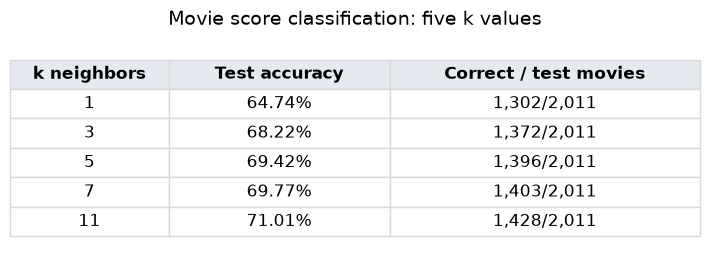

1857

In [31]:
# For every k, create, train, predict, and evaluate on the same split
k_values = [1, 3, 5, 7, 11]
records = []
for k in k_values:
    candidate = KNeighborsClassifier(n_neighbors=k)
    candidate.fit(features_train, target_train)
    predictions = candidate.predict(features_test)
    records.append({
        'k': k,
        'correct_predictions': int((predictions == target_test).sum()),
        'test_movies': len(target_test),
        'accuracy': accuracy_score(target_test, predictions),
        'training_accuracy': accuracy_score(target_train, candidate.predict(features_train))
    })

results = pd.DataFrame(records)
results.to_csv('results/lab10/knn_accuracy_results.csv', index=False)
best_k = int(results.loc[results['accuracy'].idxmax(), 'k'])
best_accuracy = float(results['accuracy'].max())
baseline_accuracy = float(target_test.value_counts(normalize=True).max())
print('GitHub: PaulChen0508 | score threshold:', score_threshold)
display(results)
print('Selected k:', best_k, '| Test accuracy:', f'{best_accuracy:.4%}')
print('Largest-class test baseline:', f'{baseline_accuracy:.4%}')

fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.axis('off')
table = ax.table(
    cellText=[[int(r.k), f'{r.accuracy:.2%}', f'{int(r.correct_predictions):,}/{int(r.test_movies):,}']
              for r in results.itertuples()],
    colLabels=['k neighbors', 'Test accuracy', 'Correct / test movies'],
    colWidths=[0.23, 0.32, 0.45], cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 1.7)
for (row, col), c in table.get_celld().items():
    c.set_edgecolor('#D9D9D9')
    if row == 0:
        c.set_facecolor('#E4EAF0')
        c.set_text_props(weight='bold')
ax.set_title('Movie score classification: five k values', fontsize=14, pad=8)
fig.tight_layout()
fig.savefig('figures/lab10/k_accuracy_table.png', dpi=240, bbox_inches='tight')
plt.show()

summary = {
    'raw_rows': len(data), 'raw_columns': data.shape[1],
    'rows_retained': len(model_data), 'rows_dropped': len(data) - len(model_data),
    'score_threshold': score_threshold,
    'class_counts': {str(k): int(v) for k, v in target.value_counts().items()},
    'train_rows': len(features_train), 'test_rows': len(features_test),
    'feature_columns_before_encoding': model_data.drop(columns='score').columns.tolist(),
    'encoded_features': features.shape[1],
    'country_threshold': country_threshold, 'language_threshold': language_threshold,
    'country_levels': model_data['country'].nunique(),
    'genre_levels': model_data['top_genre'].nunique(),
    'language_levels': model_data['top_lang'].nunique(),
    'best_k': best_k, 'best_accuracy': best_accuracy, 'baseline_accuracy': baseline_accuracy,
    'results': records,
    'dataset_url': 'https://www.kaggle.com/datasets/ashpalsingh1525/imdb-movies-dataset',
    'csv_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
    'python_version': platform.python_version(), 'pandas_version': pd.__version__,
    'sklearn_version': sklearn.__version__,
    'preprocessing': 'Numeric scaling fitted on training data only; category collapsing follows the provided lab workflow.'
}
Path('results/lab10/analysis_summary.json').write_text(json.dumps(summary, indent=2))


In [32]:
# Fit the selected model and retain its held-out predictions
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(features_train, target_train)
target_predicted = knn.predict(features_test)
assert accuracy_score(target_test, target_predicted) == best_accuracy
selected_predictions = pd.DataFrame({
    'actual_class': target_test,
    'predicted_class': target_predicted
})
selected_predictions.index.name = 'original_row'
selected_predictions.to_csv('results/lab10/selected_model_predictions.csv')
print(f'Selected model: k = {best_k}; test accuracy = {best_accuracy:.2%}')


Selected model: k = 11; test accuracy = 71.01%


## Interpretation and checks

The comparison uses the same train/test split for all five values of k. Choose the k with the highest observed test accuracy in this lab. These are exploratory comparisons on one split, not proof of future performance. For a later project, select k with validation or cross-validation and reserve a separate final test set. Zero scores are retained because the supplied dataset does not document them as missing.

The cleaned CSV retains original numeric units; the training and testing feature matrices are scaled separately using a scaler fitted only on the training data.


## Copilot conversation and verification

Codespace: special engine. Date: November 5, 2026. Model: Copilot Fusion (gpt-6-luna).

**Prompt as sent**

In LABS-10, why should the score-recoding lambda compare x > score_threshold instead of model_data['score'][x] > score_threshold? Answer in English in at most 45 words. Do not edit files.

**Actual response**

Hello Data Science Student! x is the current numeric score supplied to the lambda. model_data['score'][x] treats that score as a row index, retrieving an unrelated value or causing an indexing error, instead of comparing the current score with the threshold.

**Verification**

Yes. apply passes each score as x, so x > 65 checks that movie's score. Series[x] instead looks up an index label. The raw-score preview and the all-row assertion verify that high means >65 and low means ≤65.


## Sources and assistance

- Dataset: [Ashpal Singh, IMDB movies dataset](https://www.kaggle.com/datasets/ashpalsingh1525/imdb-movies-dataset).
- Previous score distribution: Paul Chen, LABS-7 Design, question 9, Figure 3.
- [pandas dropna](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html).
- [scikit-learn train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).
- [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html).
- [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html).

Codex assisted with the code, checks, and report preparation. The Copilot conversation is quoted separately.
